In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [4]:
df = pd.read_csv("solar_system.csv")

In [5]:
df.shape

(20, 11)

In [6]:
df.head()

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
0,Mass (10^24kg),0.330,4.87,5.97,0.073,0.642,1898,568,86.8,102,0.0130
1,Diameter (km),4879,12104,12756,3475,6792,142984,120536,51118,49528,2376
2,Density (kg/m^3),5429,5243,5514,3340,3934,1326,687,1270,1638,1850
3,Gravity (m/s^2),3.7,8.9,9.8,1.6,3.7,23.1,9.0,8.7,11.0,0.7
4,Escape Velocity (km/s),4.3,10.4,11.2,2.4,5.0,59.5,35.5,21.3,23.5,1.3


In [7]:
df.tail()

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
15,Mean Temperature (C),167,464,15,-20,-65,-110,-140,-195,-200,-225
16,Surface Pressure (bars),0,92,1,0,0.01,Unknown,Unknown,Unknown,Unknown,0.00001
17,Number of Moons,0,0,1,0,2,95,274,28,16,5
18,Ring System?,No,No,No,No,No,Yes,Yes,Yes,Yes,No
19,Global Magnetic Field?,Yes,No,Yes,No,No,Yes,Yes,Yes,Yes,Unknown


In [8]:
df.columns

Index(['Attribute', 'Mercury', 'Venus', 'Earth', 'Moon', 'Mars', 'Jupiter',
       'Saturn', 'Uranus', 'Neptune', 'Pluto'],
      dtype='str')

In [18]:
df.index

RangeIndex(start=0, stop=20, step=1)

In [23]:
orbital_period = df.iloc[10, 1:].astype(float)
perihelion = df.iloc[8, 1:].astype(float)
aphelion = df.iloc[9, 1:].astype(float)

In [24]:
semi_major_axis = (perihelion + aphelion) / 2

In [25]:
new_row = pd.DataFrame(
    [["Semi-major axis (10^6 km)"] + semi_major_axis.tolist()],
    columns=df.columns
)
df = pd.concat([df, new_row], ignore_index=True)

In [26]:
print(df.shape)

(21, 11)


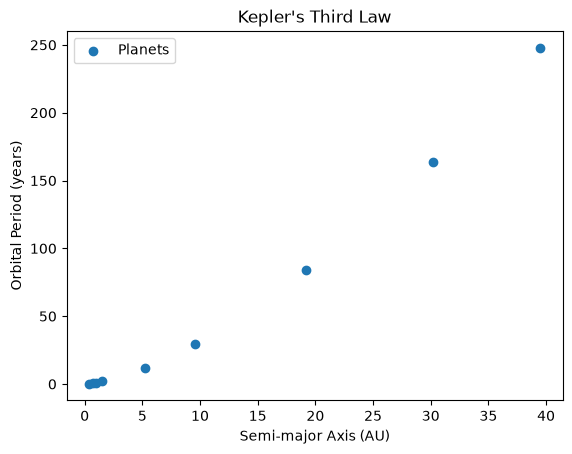

In [27]:
a = semi_major_axis.drop("Moon") / 149.6
T = orbital_period.drop("Moon") / 365.25

plt.scatter(a, T, label="Planets")

plt.xlabel("Semi-major Axis (AU)")
plt.ylabel("Orbital Period (years)")
plt.title("Kepler's Third Law")

plt.legend()
plt.show()


In [28]:
def keplers_third_law(a, m):
    return m * a ** 1.5

In [29]:
popt, pcov = curve_fit(keplers_third_law, a, T)

In [30]:
m_fit = popt[0]

In [31]:
print(f"Fit: T = {m_fit:.2f} * a^1.5")

Fit: T = 1.00 * a^1.5


In [32]:
residuals = T - keplers_third_law(a, m_fit)
chi2 = np.sum(residuals**2)
dof = len(a) - len(popt)
chi2_reduced = chi2 / dof

print("Reduced chi-squared:", chi2_reduced)

Reduced chi-squared: 0.34738252796918656


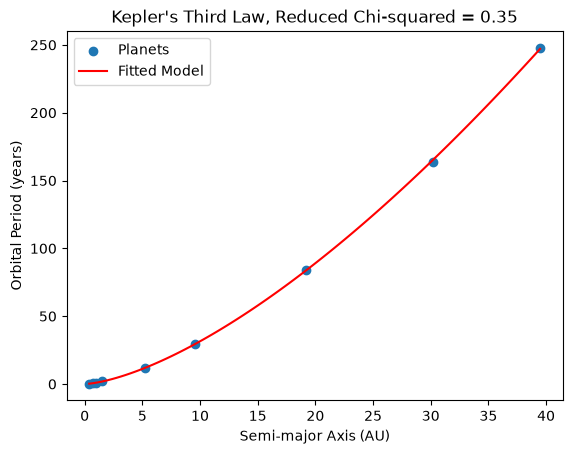

In [33]:
a_values = np.linspace(min(a), max(a), 100)

plt.scatter(a, T, label="Planets")
plt.plot(a_values, keplers_third_law(a_values, m_fit),
         color="red", label="Fitted Model")

plt.xlabel("Semi-major Axis (AU)")
plt.ylabel("Orbital Period (years)")

plt.title(f"Kepler's Third Law, Reduced Chi-squared = {chi2_reduced:.2f}")
plt.legend()
plt.show()

In [34]:
df.to_csv("kepler.csv", index=False)

In [35]:
# DONE!!